## Loss Functions and Error Metrics

### Learning Goals
* Calculate and compare regression loss functions, including Mean Squared Error (MSE) and Mean Absolute Error (MAE).
* Understand how squaring errors penalizes large deviations more heavily.
* Implement Binary Cross-Entropy loss for classification tasks and handle numerical stability using probability clipping.

---

### 1. Regression Losses: MSE and MAE

For actual values $y_i$ and model predictions $\hat{y}_i$:
* **Mean Squared Error (MSE):**
  $$
  \text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
  $$
  Squaring makes large errors especially costly.
* **Mean Absolute Error (MAE):**
  $$
  \text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|
  $$
  MAE is less sensitive to isolated large errors (outliers) than MSE.

<>:11: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:11: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
/tmp/ipykernel_3482/346899309.py:11: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  plt.xlabel("Prediction Error ($y - \hat{y}$)")


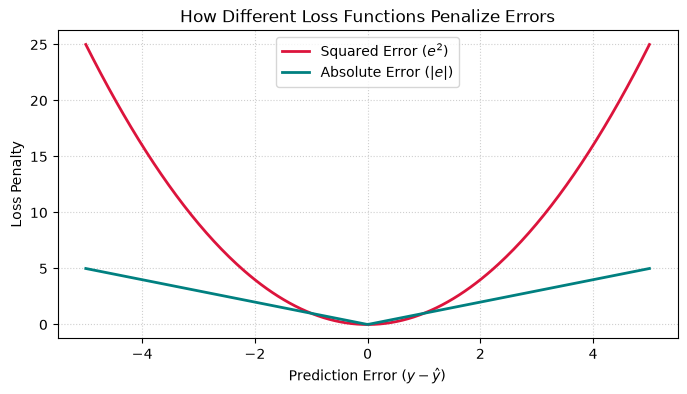

MAE:  6.20
MSE:  87.40
RMSE: 9.35


In [1]:
import numpy as np
import matplotlib.pyplot as plt

errors = np.linspace(-5, 5, 300)
squared_error = errors**2
absolute_error = np.abs(errors)

plt.figure(figsize=(8, 4))
plt.plot(errors, squared_error, color='crimson', linewidth=2, label="Squared Error ($e^2$)")
plt.plot(errors, absolute_error, color='teal', linewidth=2, label="Absolute Error ($|e|$)")
plt.xlabel("Prediction Error ($y - \hat{y}$)")
plt.ylabel("Loss Penalty")
plt.title("How Different Loss Functions Penalize Errors")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

actual = np.array([100.0, 110.0, 120.0, 130.0, 140.0])
predicted = np.array([102.0, 108.0, 125.0, 128.0, 160.0])

mae = np.mean(np.abs(actual - predicted))
mse = np.mean((actual - predicted)**2)
rmse = np.sqrt(mse)

print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")

### 2. Binary Cross-Entropy

For a binary target $y \in \{0, 1\}$ and predicted probability $p$:
$$
L = - [y \log(p) + (1 - y) \log(1 - p)]
$$
This loss penalizes confident predictions that are wrong. Probabilities must be kept strictly between zero and one to prevent taking the logarithm of zero.

In [2]:
def binary_cross_entropy(y, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-12, 1 - 1e-12)
    y = np.asarray(y, dtype=float)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

print(f"Correct Confident Prediction (y=1, p=0.9): {binary_cross_entropy([1], [0.9]):.4f}")
print(f"Wrong Confident Prediction   (y=1, p=0.1): {binary_cross_entropy([1], [0.1]):.4f}")

Correct Confident Prediction (y=1, p=0.9): 0.1054
Wrong Confident Prediction   (y=1, p=0.1): 2.3026


---

### Exercises

Try each problem before running the answer-checking code below:

1. Change the last prediction in the regression array from $160$ to $145$ and observe how MAE, MSE, and RMSE change.
2. Explain why Root Mean Squared Error (RMSE) has the same physical units as the target variable $y$.
3. Calculate the binary cross-entropy loss manually or via function for $y = 1, p = 0.9$.
4. Why might financial prediction tasks require evaluation metrics beyond simple classification accuracy?

In [3]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

# Exercise 1 Check with modified prediction
predicted_ex1 = np.array([102.0, 108.0, 125.0, 128.0, 145.0])
mae_ex1 = np.mean(np.abs(actual - predicted_ex1))
mse_ex1 = np.mean((actual - predicted_ex1)**2)
rmse_ex1 = np.sqrt(mse_ex1)
print(f"\n1. Modified Error Metrics (last prediction = 145):")
print(f"   - MAE:  {mae_ex1:.2f} (drops because penalty on outlier 160 is removed)")
print(f"   - MSE:  {mse_ex1:.2f} (drops significantly due to squaring)")
print(f"   - RMSE: {rmse_ex1:.2f}")

print("\n2. Why RMSE Has Original Units:")
print("   - Because taking the square root of squared errors ($\sqrt{\text{MSE}}$)")
print("     reverses the squaring operation, returning the metric to the original scale of $y$.")

print(f"\n3. BCE Calculation (y=1, p=0.9):")
print(f"   - Loss = -log2(0.9) approx {binary_cross_entropy([1], [0.9]):.4f}")

print("\n4. Beyond Accuracy in Finance:")
print("   - Accuracy ignores the magnitude of financial gains/losses, transaction costs,")
print("     and class imbalance; a model can be 90% accurate by always predicting 'no crash',")
print("     yet miss the single most catastrophic market drop.")

=== Exercise Solutions & Checks ===

1. Modified Error Metrics (last prediction = 145):
   - MAE:  3.20 (drops because penalty on outlier 160 is removed)
   - MSE:  12.40 (drops significantly due to squaring)
   - RMSE: 3.52

2. Why RMSE Has Original Units:
   - Because taking the square root of squared errors ($\sqrt{	ext{MSE}}$)
     reverses the squaring operation, returning the metric to the original scale of $y$.

3. BCE Calculation (y=1, p=0.9):
   - Loss = -log2(0.9) approx 0.1054

4. Beyond Accuracy in Finance:
   - Accuracy ignores the magnitude of financial gains/losses, transaction costs,
     and class imbalance; a model can be 90% accurate by always predicting 'no crash',
     yet miss the single most catastrophic market drop.


<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_3482/564072789.py:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  print("   - Because taking the square root of squared errors ($\sqrt{\text{MSE}}$)")
